# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [9]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [10]:
patients = pd.read_csv(PATIENTS_PATH)
print("shape:", patients.shape)
display(patients.dtypes)

exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X("sessions_attended:Q", title="Sessions attended (of 36)"),
        y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False),
        ),
        color=alt.Color("program:N", title="Program"),
        shape=alt.Shape("program:N", title="Program"),
        tooltip=[
            "patient_id",
            "program",
            "sessions_attended",
            "walk_distance_m",
        ],
    )
    .properties(
        title="Six-Minute Walk Distance at Discharge by Rehab Sessions Attended"
    )
)

exploratory_chart.save(EXPLORATORY_SPEC_PATH)
exploratory_chart

shape: (12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

This chart explores whether patients who attend more rehab sessions walk farther at discharge and how that compares between the Center-based and Home-based programs. Each point represents one rehab patient. Looking at the plot, there is a clear upward trend from the lower left to the upper right, showing that patients who attended more sessions generally walked a longer distance in six minutes. However, with only 12 patients who chose their own program instead of being randomized, this small observational sample only shows a correlation and cannot prove that attending more sessions causes a longer walk.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


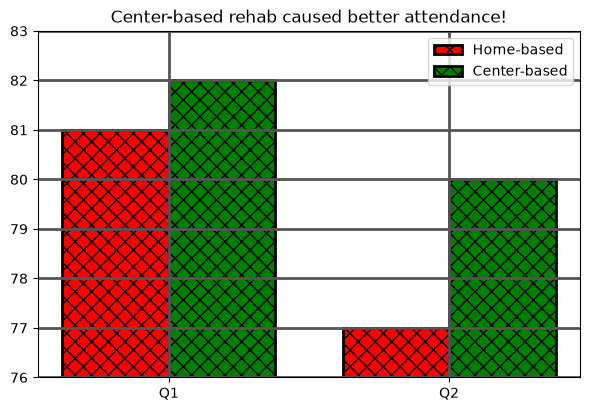

In [11]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [12]:
critique = [
    {
        "category": "unsupported claim",
        "problem": (
            "The title claims Center-based rehab caused better attendance, but"
            " observational data where patients chose their own program cannot"
            " prove causation."
        ),
        "repair": (
            "Use a neutral, descriptive title that states what the chart"
            " measures without claiming cause and effect."
        ),
    },
    {
        "category": "truncated baseline",
        "problem": (
            "The y-axis starts at 76 instead of 0, which visually exaggerates a"
            " small percentage difference between the bars."
        ),
        "repair": (
            "Start the y-axis at 0 and run it to 100 so bar lengths honestly"
            " represent the full percentage scale."
        ),
    },
    {
        "category": "missing unit",
        "problem": (
            "The axes have no labels or units, leaving the reader to guess"
            " that the numbers represent attendance percentages."
        ),
        "repair": (
            "Label the y-axis as 'Scheduled sessions attended (%)' and the"
            " x-axis as 'Quarter', and add percentage labels on the bars."
        ),
    },
    {
        "category": "color-only encoding",
        "problem": (
            "The bars use red and green with the exact same 'xx' hatch pattern,"
            " making the two programs hard to distinguish in grayscale or for"
            " colorblind readers."
        ),
        "repair": (
            "Use colorblind-safe colors (orange and blue) paired with distinct"
            " hatch patterns ('..' and '//') for each program."
        ),
    },
    {
        "category": "distracting decoration",
        "problem": (
            "Thick black bar borders, heavy dark grid lines, and unnecessary"
            " top and right borders clutter the chart without adding data."
        ),
        "repair": (
            "Remove the heavy grid and thick bar edges, hide the top and right"
            " spines, and place a clean legend outside the plot."
        ),
    },
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title claims Center-based rehab caused better attendance, but observational data where patients chose their own program cannot prove causation.
    repair: Use a neutral, descriptive title that states what the chart measures without claiming cause and effect.
truncated baseline: The y-axis starts at 76 instead of 0, which visually exaggerates a small percentage difference between the bars.
    repair: Start the y-axis at 0 and run it to 100 so bar lengths honestly represent the full percentage scale.
missing unit: The axes have no labels or units, leaving the reader to guess that the numbers represent attendance percentages.
    repair: Label the y-axis as 'Scheduled sessions attended (%)' and the x-axis as 'Quarter', and add percentage labels on the bars.
color-only encoding: The bars use red and green with the exact same 'xx' hatch pattern, making the two programs hard to distinguish in grayscale or for colorblind readers.
    repair: Use colorblind-safe colors

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

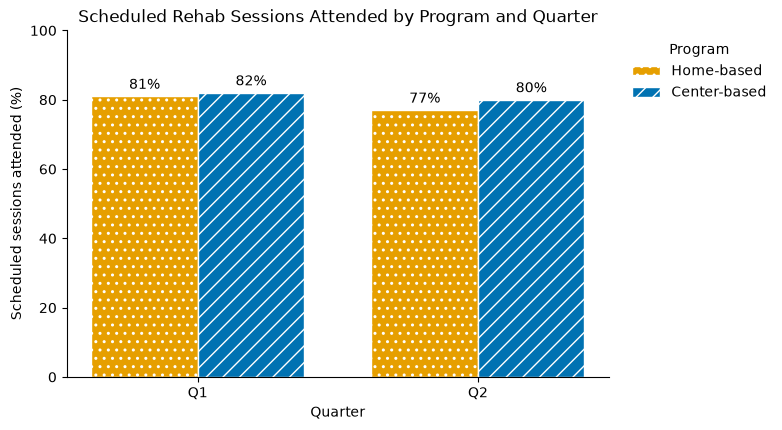

y-axis runs from 0.0 to 100.0


In [13]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

c_home = globals().get("ORANGE", "#E69F00")
c_center = globals().get("BLUE", "#0072B2")

bars_home = redesign_ax.bar(
    x - width / 2,
    home,
    width,
    label="Home-based",
    color=c_home,
    hatch="..",
    edgecolor="white",
)
bars_center = redesign_ax.bar(
    x + width / 2,
    center,
    width,
    label="Center-based",
    color=c_center,
    hatch="//",
    edgecolor="white",
)

redesign_ax.bar_label(bars_home, fmt="%d%%", padding=3)
redesign_ax.bar_label(bars_center, fmt="%d%%", padding=3)

redesign_ax.set_ylim(0, 100)
redesign_ax.set_xticks(x, quarters)
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_title("Scheduled Rehab Sessions Attended by Program and Quarter")

redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)
redesign_ax.legend(
    title="Program", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False
)

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [14]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup)

question = (
    "How does the percentage of patients meeting the weekly exercise goal"
    " change from visit 1 to visit 4 in the Home-based and Center-based"
    " programs?"
)
audience = (
    "The rehab program coordinator deciding where to add follow-up coaching"
    " support."
)
intended_claim = (
    "Goal attainment rises across visits in both programs, but by visit 4"
    " Center-based is at 79% compared with 70% for Home-based (a 9-point gap)."
)
y_measure = (
    "Percentage of patients seen at the visit who met the 150-minute weekly"
    " exercise goal (%)"
)
grain = "One rehab program at one follow-up visit"

data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[["program", "visit_number", "goal_met_pct"]]
supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

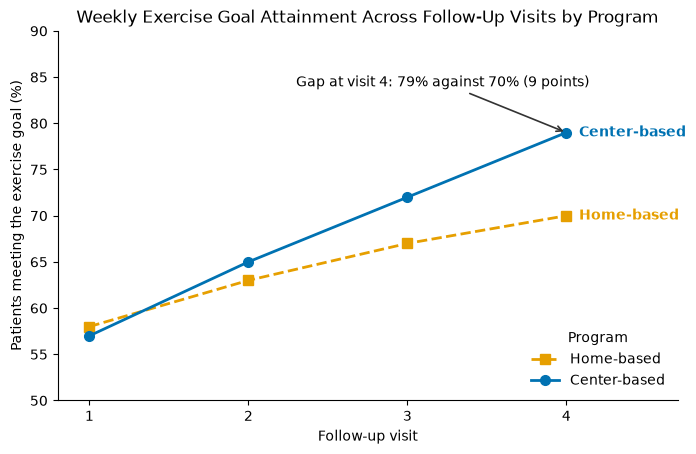

In [15]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

c_home = globals().get("ORANGE", "#E69F00")
c_center = globals().get("BLUE", "#0072B2")

explanatory_ax.plot(
    home_goals["visit_number"],
    home_goals["goal_met_pct"],
    color=c_home,
    marker="s",
    linestyle="--",
    linewidth=2,
    markersize=7,
    label="Home-based",
)
explanatory_ax.plot(
    center_goals["visit_number"],
    center_goals["goal_met_pct"],
    color=c_center,
    marker="o",
    linestyle="-",
    linewidth=2,
    markersize=7,
    label="Center-based",
)

explanatory_ax.text(
    4.08,
    float(home_goals.loc[home_goals["visit_number"] == 4, "goal_met_pct"].iloc[0]),
    "Home-based",
    color=c_home,
    va="center",
    fontweight="bold",
)
explanatory_ax.text(
    4.08,
    float(center_goals.loc[center_goals["visit_number"] == 4, "goal_met_pct"].iloc[0]),
    "Center-based",
    color=c_center,
    va="center",
    fontweight="bold",
)


explanatory_ax.annotate(
    "Gap at visit 4: 79% against 70% (9 points)",
    xy=(4, 79),
    xytext=(2.3, 84),
    arrowprops={"arrowstyle": "->", "color": "#333333", "lw": 1.2},
    fontsize=10,
)

explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_xlim(0.8, 4.7)
explanatory_ax.set_ylim(50, 90)
explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_title(
    "Weekly Exercise Goal Attainment Across Follow-Up Visits by Program"
)
explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)
explanatory_ax.legend(title="Program", loc="lower right", frameon=False)

explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [16]:
text_alternative = (
    f"Line chart showing the percentage of patients meeting the 150-minute"
    f" weekly exercise goal (%) on the y-axis across follow-up visits 1 to 4 on"
    f" the x-axis for two programs. Home-based rehab rises from"
    f" {int(home_goals['goal_met_pct'].iloc[0])}% at visit 1 to"
    f" {int(home_goals['goal_met_pct'].iloc[-1])}% at visit 4, while"
    f" Center-based rehab rises from"
    f" {int(center_goals['goal_met_pct'].iloc[0])}% at visit 1 to"
    f" {int(center_goals['goal_met_pct'].iloc[-1])}% at visit 4, leaving a"
    f" 9-point gap (79% against 70%) at visit 4. Because patients chose their"
    f" own program and each visit covers only about 45 returning patients per"
    f" program, this gap is descriptive and could reflect self-selection,"
    f" dropout, or chance rather than a causal effect."
)


visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}


with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)


with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative + "\n")

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

In critique_redesign.png, the two programs are distinguishable in grayscale because the Home-based bars use a dotted pattern and the Center-based bars use diagonal stripes. In explanatory_chart.png, a dashed line with square markers and a solid line with circular markers distinguish the programs, and each line is labeled directly. The annotation arrow points to the Center-based result of 79% at visit 4. The label reports the observed difference of 9 percentage points between 79% and 70% without attributing it to the program. Both saved images display all text without clipping or overlap. The export used a tight bounding box, and the axis limits left room for the direct labels and annotation arrow. Patients chose their own rehabilitation programs, only about 45 patients were observed per visit, and some dropped out over time. These limitations prevent the charts from establishing whether the program caused the observed difference.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [17]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m